# Modules & Packages

When a program grows, you split it into files. A **module** is one `.py` file. A **package** is a folder of modules. The `import` statement loads code from modules and packages.

**After this lesson you can:**

1. Import from the standard library and from installed packages.
2. Create your own module and package.
3. Explain how Python finds modules (`sys.path`).
4. Use the `if __name__ == "__main__":` pattern.

## 1. Import Styles

| Statement | Result |
| :--- | :--- |
| `import math` | use `math.sqrt(2)` |
| `import numpy as np` | short alias: `np.array(...)` |
| `from statistics import mean, median` | use `mean(...)` directly |
| `from math import *` | imports every public name; **avoid**: names become unclear |

The **standard library** comes with Python. It has more than 200 modules: files, dates, maths, JSON, HTTP, testing, and more.

In [1]:
import math
import statistics as st
from collections import Counter
from datetime import date, timedelta

print("sqrt(2)          :", math.sqrt(2))
print("mean / median    :", st.mean([3, 7, 8, 12]), st.median([3, 7, 8, 12]))
print("most common words:", Counter("to be or not to be".split()).most_common(2))
print("100 days from now:", date.today() + timedelta(days=100))

sqrt(2)          : 1.4142135623730951
mean / median    : 7.5 7.5
most common words: [('to', 2), ('be', 2)]
100 days from now: 2027-02-24


## 2. Create Your Own Module and Package

The cell below writes a small package to a temporary folder:

```
shop/
├── __init__.py      # marks the folder as a package; runs on import
├── pricing.py       # a module
└── inventory.py     # a module that imports from pricing
```

Then it imports the package. In a real project these files live in your repository, not in a notebook.

In [2]:
import sys
import tempfile
import textwrap
from pathlib import Path

workdir = Path(tempfile.mkdtemp())
pkg = workdir / "shop"
pkg.mkdir()
(pkg / "__init__.py").write_text('"""A tiny example package."""\nfrom .pricing import with_vat\n__version__ = "0.1.0"\n')
(pkg / "pricing.py").write_text(textwrap.dedent("""
    VAT_RATE = 0.20

    def with_vat(net: float) -> float:
        # Return the price including value-added tax.
        return round(net * (1 + VAT_RATE), 2)
"""))
(pkg / "inventory.py").write_text(textwrap.dedent("""
    from .pricing import with_vat      # relative import inside the package

    def stock_value(items: dict[str, tuple[int, float]]) -> float:
        # items: name -> (quantity, net price). Return the total value including VAT.
        return sum(qty * with_vat(price) for qty, price in items.values())

    if __name__ == "__main__":         # runs only with: python -m shop.inventory
        print(stock_value({"pen": (10, 1.5)}))
"""))

sys.path.insert(0, str(workdir))       # let Python find the package
import shop
from shop.inventory import stock_value

print("package version:", shop.__version__)
print("with_vat(100)  :", shop.with_vat(100))
print("stock value    :", stock_value({"pen": (10, 1.5), "notebook": (4, 3.0)}))
print("module file    :", Path(shop.inventory.__file__).relative_to(workdir))

package version: 0.1.0
with_vat(100)  : 120.0
stock value    : 32.4
module file    : shop/inventory.py


## 3. How Python Finds a Module

On `import shop`, Python searches the folders in `sys.path`, in order:

1. the folder of the script (or the current folder of the notebook),
2. folders in the `PYTHONPATH` environment variable,
3. the standard library,
4. `site-packages` of the active environment, where `uv` and `pip` install packages.

Python imports a module only once per process. Later imports reuse the module object from `sys.modules`.

In [3]:
home = str(Path.home())
for p in sys.path[:6]:
    print(" ", p.replace(str(Path.cwd().parent), "<repo>").replace(home, "~"))
print("...")
print("'shop' is cached in sys.modules:", "shop" in sys.modules)

  /tmp/tmpcf2t8wos
  ~/.local/share/uv/python/cpython-3.12.16-linux-x86_64-gnu/lib/python312.zip
  ~/.local/share/uv/python/cpython-3.12.16-linux-x86_64-gnu/lib/python3.12
  ~/.local/share/uv/python/cpython-3.12-linux-x86_64-gnu/lib/python3.12/lib-dynload
  
  <repo>/.venv/lib/python3.12/site-packages
...
'shop' is cached in sys.modules: True


## 4. `__name__ == "__main__"`

Every module has a variable `__name__`. When you run a file directly (`python file.py` or `python -m package.module`), `__name__` is `"__main__"`. When another module imports it, `__name__` is the module name. Put code that should run only as a script under the `if __name__ == "__main__":` guard.

In [4]:
import subprocess

result = subprocess.run([sys.executable, "-m", "shop.inventory"], cwd=workdir, capture_output=True, text=True)
print("python -m shop.inventory ->", result.stdout.strip())
print("__name__ inside the imported module:", shop.inventory.__name__)

python -m shop.inventory -> 18.0
__name__ inside the imported module: shop.inventory


## 5. Import Cost

Importing a module runs its code. Large packages take time to import. The cell measures the import time of some packages in a fresh Python process, so the notebook's cache does not affect the result.

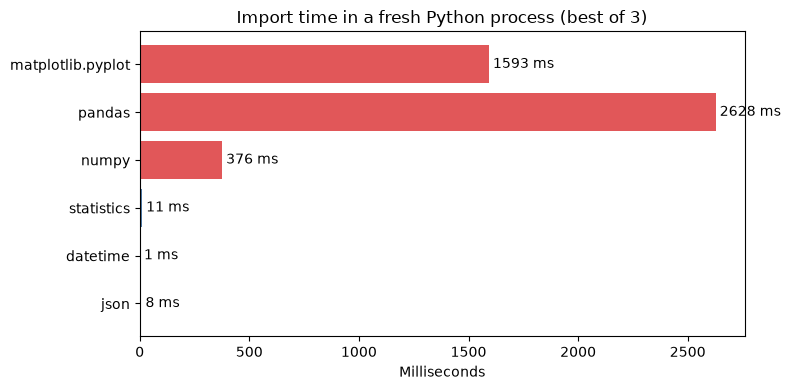

pandas takes 331x longer to import than json


In [5]:
import matplotlib.pyplot as plt

def import_time(module: str, runs: int = 3) -> float | None:
    """Best of several runs: the first run also includes reading the files from disk (cold cache)."""
    code = f"import time; t = time.perf_counter(); import {module}; print(time.perf_counter() - t)"
    times = []
    for _ in range(runs):
        r = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)
        if r.returncode != 0:
            return None
        times.append(float(r.stdout) * 1000)
    return min(times)

modules = ["json", "datetime", "statistics", "numpy", "pandas", "matplotlib.pyplot"]
times = {m: import_time(m) for m in modules}
times = {m: t for m, t in times.items() if t is not None}

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(list(times), list(times.values()), color=["#4E79A7" if t < 50 else "#E15759" for t in times.values()])
for i, t in enumerate(times.values()):
    ax.text(t, i, f" {t:.0f} ms", va="center")
ax.set(title="Import time in a fresh Python process (best of 3)", xlabel="Milliseconds")
plt.tight_layout()
plt.show()
if "pandas" in times and "json" in times:
    print(f"pandas takes {times['pandas'] / times['json']:.0f}x longer to import than json")

Small standard-library modules import in a few milliseconds. Large libraries such as pandas and matplotlib take one or two orders of magnitude longer, because they import many sub-modules and compiled extensions. The exact numbers depend on your disk: on a slow or network drive, the first import can take several seconds.

*Insight: Organise code by responsibility: one module per topic, one package per project. Import at the top of the file, and never use `from x import *`; explicit names show where each function comes from.*

## Real-World Use Case or Analogy

A package is like a **library building**. Each module is a shelf with books about one topic. `import` is a request to the librarian (`sys.path` is the list of rooms to search). The first request takes time; after that, the book stays on your desk (`sys.modules`).

Every Python project in industry is a package with a `pyproject.toml`. The data team's `features` package, the platform team's `logging` package and open-source packages from PyPI are all imported the same way. M02 shows how to build and publish such a package with uv.